In [1]:
import math, time, numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from torchvision.datasets import EuroSAT
from sklearn.model_selection import train_test_split

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', device, '| torch', torch.__version__)
if device == 'cpu':
    print('WARNING: no GPU. Training would take hours: Runtime -> Change runtime type -> GPU.')
torch.backends.cudnn.benchmark = True                               # faster convolutions on GPU
plt.rcParams['figure.figsize'] = (10, 4)

# ----- every design choice in one place, fixed BEFORE looking at any test result
PATCH, DIM, DEPTH, HEADS, MLP_RATIO = 8, 128, 3, 4, 2               # tiny ViT: 64x64 image -> 8x8 = 64 patch tokens
STEPS, BATCH, LR, WD = 2000, 128, 1e-3, 0.05                       # same recipe and same number of steps for every run
SIZES = {'small': 50, 'medium': 250, 'all': None}                  # training images per class (None = the whole training pool)
SEEDS = (0, 1, 2)                                                   # each run is repeated with three seeds

device: cuda | torch 2.11.0+cu130


100%|██████████| 94.3M/94.3M [00:00<00:00, 103MB/s]


loaded 27,000 images in 7 s; shape (27000, 64, 64, 3)


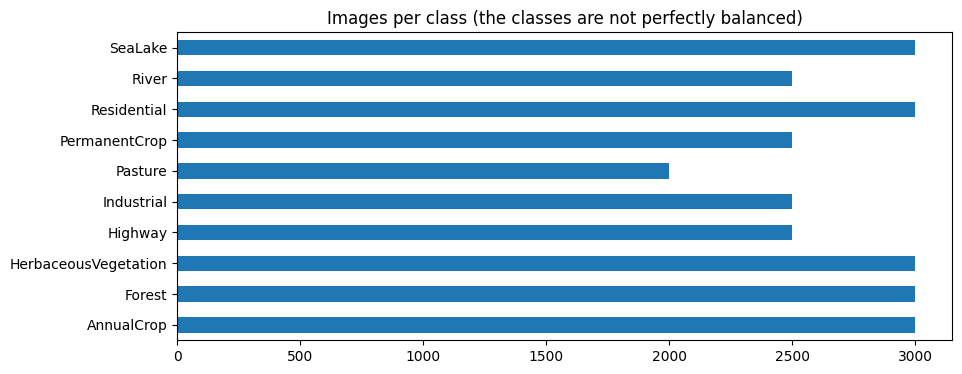

In [2]:
ds = EuroSAT(root='data', download=True)
classes = ds.classes
t0 = time.time()
X_all = np.stack([np.asarray(ds[i][0], dtype=np.uint8) for i in range(len(ds))])  # (27000, 64, 64, 3)
y_all = np.asarray(ds.targets)
print(f'loaded {len(X_all):,} images in {time.time() - t0:.0f} s; shape {X_all.shape}')
assert X_all.shape == (27000, 64, 64, 3) and len(classes) == 10

counts = pd.Series(y_all).value_counts().sort_index()
counts.index = classes
counts.plot.barh(title='Images per class (the classes are not perfectly balanced)'); plt.show()

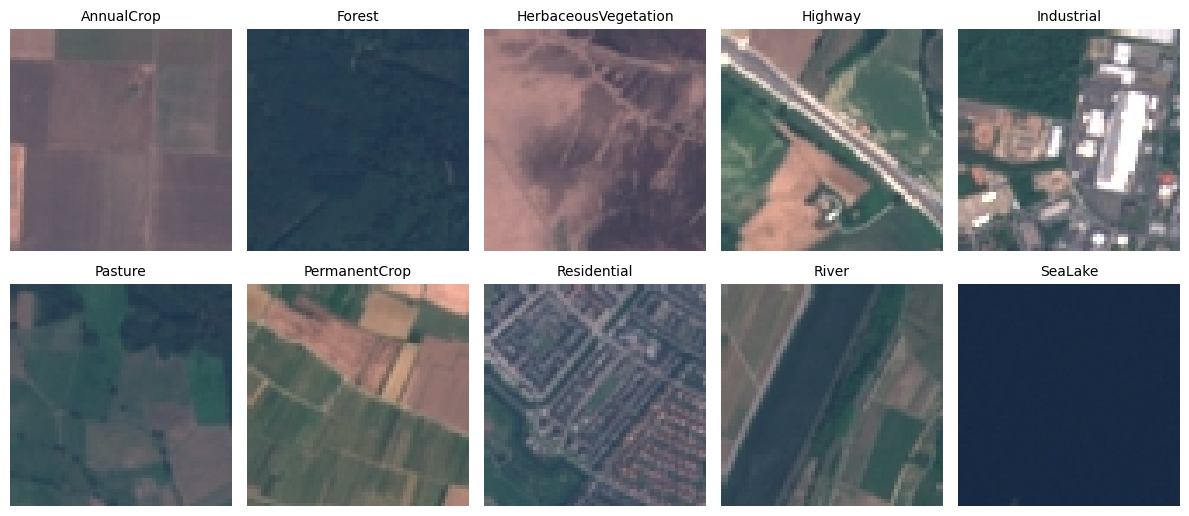

In [8]:
fig, axs = plt.subplots(2, 5, figsize=(12, 5.4))
for c, ax in enumerate(axs.ravel()):
  ax.imshow(X_all[np.flatnonzero(y_all == c)[0]]); ax.set_title(classes[c], fontsize = 10); ax.axis('off')
plt.tight_layout(); plt.show()

In [11]:
idx_train, idx_test = train_test_split(np.arange(len(y_all)), test_size=0.2, stratify=y_all, random_state=42)

def subset(n_per_class, seed):
  if n_per_class is None:
    return np.sort(idx_train)
  r = np.random.default_rng(seed)
  return np.sort(np.concatenate([r.permutation(idx_train[y_all[idx_train] == c])[:n_per_class] for c in range(10)]))

train_sets = {(size, seed): subset(n, seed) for size, n in SIZES.items() for seed in SEEDS}
for seed in SEEDS:
  assert set(train_sets[('small', seed)]) <= set(train_sets[('medium', seed)]) <= set(train_sets[('all', seed)])
assert not set(idx_train) & set(idx_test)
print({size: len(train_sets[(size, SEEDS[0])])for size in SIZES}, '| test:', len(idx_test))

{'small': 500, 'medium': 2500, 'all': 21600} | test: 5400


In [13]:
X_t = torch.from_numpy(X_all).permute(0, 3, 1, 2).contiguous().to(device)
y_t = torch.from_numpy(y_all).long().to(device)
tr_pool = torch.as_tensor(idx_train, device = device)
mean = X_t[tr_pool].float().mean((0, 2, 3), keepdim=True) / 255
std = X_t[tr_pool].float().std((0, 2, 3), keepdim=True) / 255
def to_float(xb):
  return (xb.float() / 255 - mean) / std

one image (1, 3, 64, 64) -> (1, 64, 192) (patches, numbers per patch)


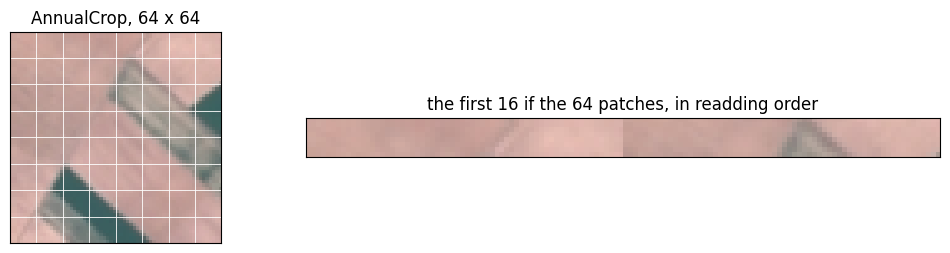

In [18]:
def patchify(x, p=PATCH):
  B, C, H, W = x.shape
  t = x.unfold(2, p, p).unfold(3, p, p)
  t = t.permute(0, 2, 3, 1, 4, 5)
  return t.reshape(B, (H//p) * (W//p), C * p * p)

def unpatchify(t, p=PATCH, C = 3):
  B, N, _ = t.shape
  g = int(round(math.sqrt(N)))
  t = t.reshape(B, g, g, C, p, p).permute(0, 3, 1, 4, 2, 5)
  return t.reshape(B, C, g*p, g*p)

x0 = X_t[torch.as_tensor(idx_test[:1], device = device)].float().cpu()/ 255
P0 = patchify(x0)

print('one image', tuple(x0.shape), '->', tuple(P0.shape), '(patches, numbers per patch)')
assert torch.equal(unpatchify(P0), x0)

fig, axs = plt.subplots(1, 2, figsize=(12, 3.6), gridspec_kw = {'width_ratios': [1, 3]})
axs[0].imshow(x0[0].permute(1, 2, 0)); axs[0].set_title(f'{classes[y_all[idx_test[0]]]}, 64 x 64')
for k in range(1, 8):
  axs[0].axhline(k*PATCH - .5, color = 'w', lw = .6); axs[0].axvline(k * PATCH - .5, color = 'w', lw=.6)
strip = P0[0, :16].reshape(16, 3, PATCH, PATCH).permute(0, 2, 3, 1)
axs[1].imshow(torch.cat(list(strip), dim = 1)); axs[1].set_title('the first 16 if the 64 patches, in readding order')
for a in axs: a.set_xticks([]); a.set_yticks([])
plt.show()

In [19]:
torch.manual_seed(0)
conv = nn.Conv2d(3, DIM, kernel_size=PATCH, stride=PATCH)
lin = nn.Linear(3 * PATCH * PATCH, DIM)
with torch.no_grad():
    lin.weight.copy_(conv.weight.reshape(DIM, -1))
    lin.bias.copy_(conv.bias)
    tok_lin = lin(patchify(x0))
    tok_conv = conv(x0).flatten(2).transpose(1, 2)
print('largest difference:', (tok_lin - tok_conv).abs().max().item())
assert torch.allclose(tok_lin, tok_conv, atol=1e-5)

largest difference: 1.3113021850585938e-06


In [20]:
class Attention(nn.Module):
    def __init__(self, dim, heads):
        super().__init__()
        self.heads = heads
        self.qkv = nn.Linear(dim, 3 * dim)                          # queries, keys and values in one matrix
        self.proj = nn.Linear(dim, dim)
        self.last_attn = None                                       # kept to look inside after training

    def forward(self, x):
        B, N, D = x.shape
        h, dh = self.heads, D // self.heads
        q, k, v = self.qkv(x).reshape(B, N, 3, h, dh).permute(2, 0, 3, 1, 4)  # each (B, h, N, dh)
        attn = (q @ k.transpose(-2, -1)) / math.sqrt(dh)            # (B, h, N, N) scores
        attn = attn.softmax(dim=-1)                                 # each row sums to 1
        self.last_attn = attn.detach()
        out = (attn @ v).transpose(1, 2).reshape(B, N, D)           # weighted mix of values
        return self.proj(out)

class Block(nn.Module):
    def __init__(self, dim, heads, mlp_ratio):
        super().__init__()
        self.norm1, self.attn = nn.LayerNorm(dim), Attention(dim, heads)
        self.norm2 = nn.LayerNorm(dim)
        self.mlp = nn.Sequential(nn.Linear(dim, mlp_ratio * dim), nn.GELU(), nn.Linear(mlp_ratio * dim, dim))

    def forward(self, x):
        x = x + self.attn(self.norm1(x))                            # the meeting: tokens exchange information
        x = x + self.mlp(self.norm2(x))                             # the homework: each token on its own
        return x
class TinyViT(nn.Module):
    def __init__(self, img=64, patch=PATCH, dim=DIM, depth=DEPTH, heads=HEADS, mlp_ratio=MLP_RATIO,
                 n_classes=10, use_pos=True):
        super().__init__()
        n_patches = (img // patch) ** 2
        self.embed = nn.Conv2d(3, dim, kernel_size=patch, stride=patch)         # the patch embedding
        self.cls = nn.Parameter(0.02 * torch.randn(1, 1, dim))                 # the [CLS] token
        self.pos = nn.Parameter(0.02 * torch.randn(1, n_patches + 1, dim)) if use_pos else None
        self.blocks = nn.ModuleList([Block(dim, heads, mlp_ratio) for _ in range(depth)])
        self.norm = nn.LayerNorm(dim)
        self.head = nn.Linear(dim, n_classes)

    def forward(self, x):
        t = self.embed(x).flatten(2).transpose(1, 2)                           # (B, 64, dim): one token per patch
        t = torch.cat([self.cls.expand(len(t), -1, -1), t], dim=1)             # prepend [CLS] -> (B, 65, dim)
        if self.pos is not None:
            t = t + self.pos                                                    # add position
        for blk in self.blocks:
            t = blk(t)
        return self.head(self.norm(t[:, 0]))                                   # classify from [CLS] only